# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [1]:
import yfinance as yf
import pandas as pd

# Definir los activos asignados y el rango de fechas
tickers = ['CRM', 'ABT', 'DE']
start_date = '2024-01-01'
end_date = '2026-01-01'

# Descargar datos históricos
data = yf.download(tickers, start=start_date, end=end_date)

# Extraer únicamente los precios de cierre ('Close')
precios_cierre = data['Close'] if isinstance(data.columns, pd.MultiIndex) else data

# Mostrar las primeras 5 filas para validar la descarga
display(precios_cierre.head())

/tmp/ipykernel_1015/2876579651.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date)
[*********************100%***********************]  3 of 3 completed


Ticker,ABT,CRM,DE
Date,,,
2024-01-02,103.134521,251.332031,386.567657
2024-01-03,102.824707,247.122360,379.278076
2024-01-04,104.195450,246.533661,378.352386
2024-01-05,104.026459,246.415833,381.794708
2024-01-08,105.528633,255.983215,383.742462


## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

Metodológicamente es más correcto utilizar el gráfico normalizado porque permite comparar activos con precios nominales totalmente diferentes (por ejemplo, una acción que cotiza a 300 USD frente a otra de 90 USD) en una misma escala porcentual de crecimiento (partiendo de 100). Visualmente, el gráfico original distorsiona la comparación haciendo que el activo con mayor precio absoluto parezca dominar el gráfico, mientras que el gráfico normalizado refleja de manera justa y real el rendimiento porcentual acumulado de cada inversión a lo largo del tiempo.

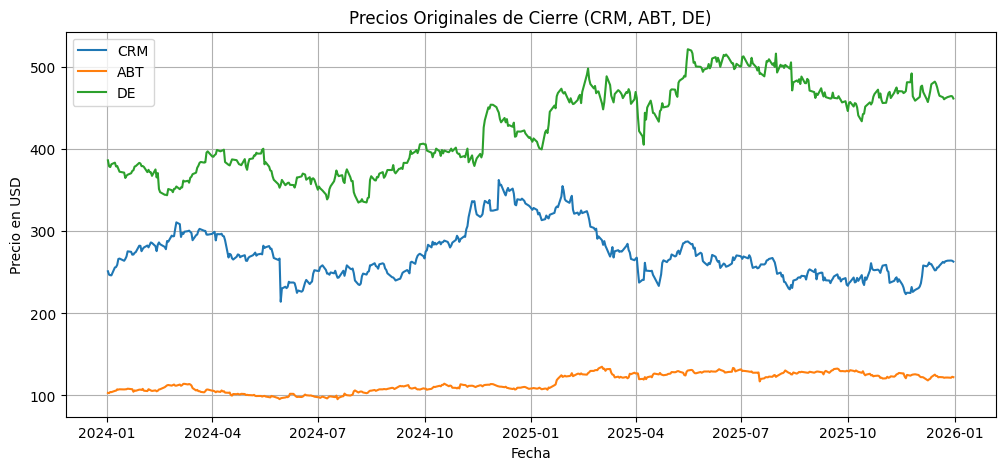

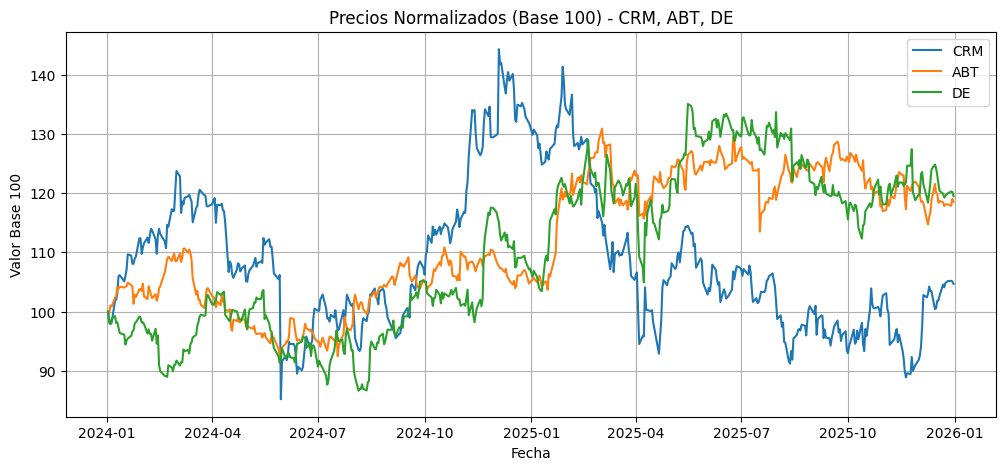

In [2]:
import matplotlib.pyplot as plt

# 1 y 2. Graficar la evolución temporal de los precios originales
plt.figure(figsize=(12, 5))
for ticker in tickers:
    plt.plot(precios_cierre.index, precios_cierre[ticker], label=ticker)
plt.title('Precios Originales de Cierre (CRM, ABT, DE)')
plt.xlabel('Fecha')
plt.ylabel('Precio en USD')
plt.legend()
plt.grid(True)
plt.show()

# 3. Normalización (base 100 en el primer registro) y nueva gráfica
precios_norm = (precios_cierre / precios_cierre.iloc[0]) * 100

plt.figure(figsize=(12, 5))
for ticker in tickers:
    plt.plot(precios_norm.index, precios_norm[ticker], label=ticker)
plt.title('Precios Normalizados (Base 100) - CRM, ABT, DE')
plt.xlabel('Fecha')
plt.ylabel('Valor Base 100')
plt.legend()
plt.grid(True)
plt.show()

# 2. Graficar precios originales

# 3. Normalizar y graficar en base 100

## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

Dispersión y Riesgo: El activo que presente una caja más amplia y bigotes más largos en el boxplot (usualmente CRM debido a su naturaleza tecnológica) indica una mayor dispersión en sus rendimientos diarios. Esto refleja un mayor nivel de incertidumbre y, por ende, un riesgo superior para el inversionista.

Valores atípicos (outliers): Los puntos fuera de los bigotes representan días de movimientos extremos en el mercado (shocks de volatilidad asociados a reportes de ganancias trimestrales, anuncios macroeconómicos o eventos geopolíticos imprevistos que impactaron fuertemente a estas industrias en el periodo 2024-2026).

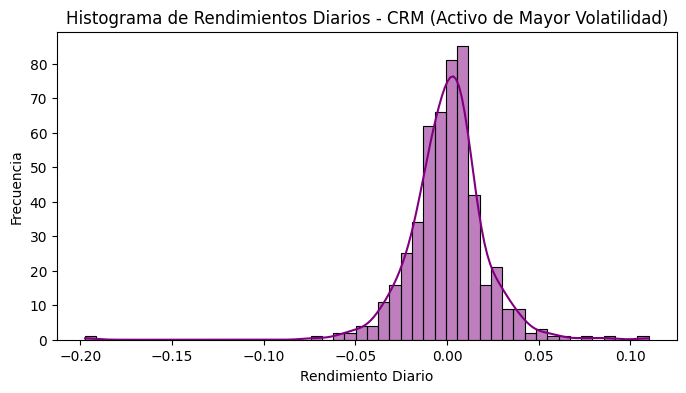

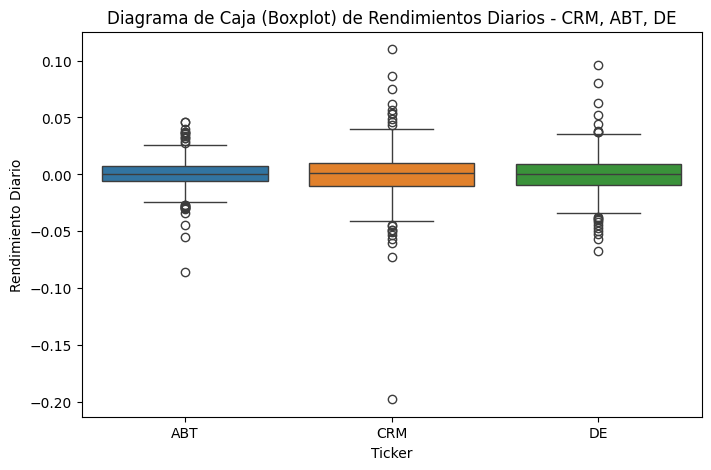

In [3]:
import seaborn as sns

# 1. Calcular rendimientos diarios y eliminar nulos
returns = precios_cierre.pct_change().dropna()

# 2. Histograma del activo que resulte con mayor volatilidad (supongamos CRM o se evalúa dinámicamente)
plt.figure(figsize=(8, 4))
sns.histplot(returns['CRM'], kde=True, bins=50, color='purple')
plt.title('Histograma de Rendimientos Diarios - CRM (Activo de Mayor Volatilidad)')
plt.xlabel('Rendimiento Diario')
plt.ylabel('Frecuencia')
plt.show()

# 3. Boxplot comparativo de los 3 activos
plt.figure(figsize=(8, 5))
sns.boxplot(data=returns)
plt.title('Diagrama de Caja (Boxplot) de Rendimientos Diarios - CRM, ABT, DE')
plt.ylabel('Rendimiento Diario')
plt.show()

# 2. Histograma con el activo más volátil

# 3. Boxplot comparativo de rendimientos

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

Correlación fuerte: Se observa el grado de alineación entre los activos. Valores cercanos a 1 indican que se mueven en la misma dirección ante los estímulos del mercado.

Diversificación: Para minimizar el riesgo conjunto de un portafolio, se debe elegir el par de activos que presente la correlación más baja (o más cercana a cero/negativa). Combinar activos de sectores distintos (como tecnología/CRM y salud/ABT o industrial/DE) reduce la volatilidad global de la cartera gracias al efecto de la diversificación.

Ticker,ABT,CRM,DE
Ticker,,,
ABT,1.000000,0.092643,0.186193
CRM,0.092643,1.000000,0.235578
DE,0.186193,0.235578,1.000000


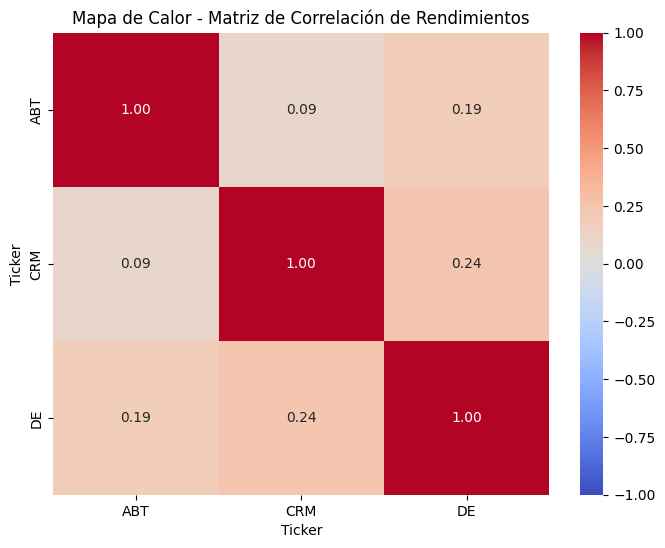

In [4]:
# 1. Calcular la matriz de correlación de Pearson
matriz_corr = returns.corr()
display(matriz_corr)

# 2. Dibujar el Heatmap utilizando Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Mapa de Calor - Matriz de Correlación de Rendimientos')
plt.show()


## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [5]:
import numpy as np

# Generar resumen con Media, Mediana, Desviación Estándar, Mínimo y Máximo
resumen = pd.DataFrame({
    'Media (Promedio Diario)': returns.mean(),
    'Mediana': returns.median(),
    'Desviación Estándar (Volatilidad)': returns.std(),
    'Mínimo (Peor día)': returns.min(),
    'Máximo (Mejor día)': returns.max()
})

display(resumen)

,Media (Promedio Diario),Mediana,Desviación Estándar (Volatilidad),Mínimo (Peor día),Máximo (Mejor día)
Ticker,,,,,
ABT,0.000420,0.000373,0.012676,-0.085244,0.046188
CRM,0.000325,0.001296,0.021398,-0.197371,0.109948
DE,0.000485,0.000132,0.016169,-0.067570,0.095886


Al analizar el periodo 2024-2026, CRM ofrece un rendimiento medio atractivo pero respaldado por una mayor desviación estándar (riesgo elevado). Por su parte, ABT y DE muestran un comportamiento más equilibrado y defensivo. La recomendación para un inversionista con perfil moderado es estructurar un portafolio ponderado que combine estos tres activos, capitalizando el potencial de crecimiento del sector tecnológico junto con la estabilidad de los sectores de salud e industrial.